# Foundations of Deep Learning — Exercise Sheet 2 (Part B: Programming)

This notebook contains Task 5 of Exercise Sheet 2: **regression with neural networks, underfitting and overfitting**.

* Fill in all parts marked with `TODO`. Solve Part A of the sheet first — several cells check your code against your pen & paper results.
* Before the presentation: **Restart the kernel and run all cells** (`Kernel → Restart & Run All`) so that all outputs are visible. The whole notebook runs in well under a minute.
* You need `numpy` and `matplotlib`. On Google Colab everything is pre-installed. Do not use scikit-learn, PyTorch, etc.
* Every group member must be able to explain every line of code in this notebook (cells marked *given* only on a high level).

In [3]:
import matplotlib.pyplot as plt
import numpy as np

---
## The data (given)

We sample noisy points of $y = \sin(\pi x)$ on $[-1, 1]$. The **training set is deliberately tiny (12 points)**;
validation and test set have 200 points each. `X_big, y_big` is a second, larger training set of 200 points that we use in 5(c).

All arrays have shape `(n, 1)`: one data point per row, one feature per column — exactly as $\mathbf{X}$ in the lecture.

shapes: (12, 1) (12, 1) (200, 1) (200, 1)


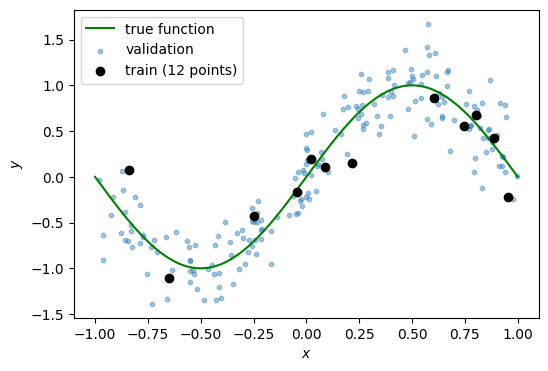

In [4]:
def true_function(x):
    return np.sin(np.pi * x)


def make_data(n, rng, noise=0.25):
    x = rng.uniform(-1, 1, (n, 1))
    return x, true_function(x) + noise * rng.normal(size=(n, 1))


rng = np.random.default_rng(4)
X_train, y_train = make_data(12, rng)
X_val, y_val     = make_data(200, rng)
X_test, y_test   = make_data(200, rng)
X_big, y_big     = make_data(200, np.random.default_rng(99))

print("shapes:", X_train.shape, y_train.shape, X_val.shape, X_test.shape)
plt.figure(figsize=(6, 4))
x_plot = np.linspace(-1, 1, 400).reshape(-1, 1)
plt.plot(x_plot, true_function(x_plot), "g", label="true function")
plt.scatter(X_val, y_val, s=10, alpha=0.4, label="validation")
plt.scatter(X_train, y_train, c="k", zorder=3, label="train (12 points)")
plt.legend(); plt.xlabel("$x$"); plt.ylabel("$y$")
plt.show()

---
## Task 5(a): Forward pass and loss

A network is stored as a list of layers `params = [(W1, b1), (W2, b2), ..., (WL, bL)]`.
As in the lecture, `W` of a layer has shape `(n_out, n_in)` and `b` has shape `(n_out,)`.
The layer sizes are described by a list, e.g. `sizes = [1, 16, 16, 1]` (input, two hidden layers, output).

`init_params` (given) creates random weights. Note: `sizes = [1, 1]` is a network **without hidden layer**, i.e. plain **linear regression** $\hat{y} = w x + b$.

Implement:
* `relu(z)` — element-wise $\max(0, z)$.
* the two missing lines in `forward(X, params)`. It applies all layers to the whole batch `X` (shape `(n, n_in)`), with a **ReLU after every layer except the last one**.
  The loop over the layers is given. It returns the output (shape `(n, n_out)`) **and** the list `acts = [X, h_1, ..., output]` of the outputs of all layers (needed for the backward pass).
  *Hint:* `h` has one data point per row — how do you compute $\mathbf{W}\mathbf{h}_i + \mathbf{b}$ for all rows at once, without a loop over the data points?
* `mse(y_hat, y)` — the mean squared error.

In [9]:
def init_params(sizes, seed=0):
    """Given: random weights (scaled by sqrt(2 / n_in)) and zero biases for the layer sizes."""
    rng = np.random.default_rng(seed)
    return [(rng.normal(0, np.sqrt(2 / n_in), (n_out, n_in)), np.zeros(n_out))
            for n_in, n_out in zip(sizes[:-1], sizes[1:])]

def relu(z):
    return np.maximum(0, z)

def forward(X, params):
    """Returns (output, acts) with acts = [X, h_1, ..., output]."""
    acts = [X]
    h = X
    # h (12,1) (16,1) w
    for i, (W, b) in enumerate(params):      # loop over the layers
        z = h @ W.T + b   # TODO: W h + b for all rows of h at once
        if i < len(params) - 1:
            h = relu(z)   # TODO: hidden layer -> ReLU
        else:
            h = z                            # output layer: no activation
        acts.append(h)
    return h, acts


def mse(y_hat, y):
    return np.mean((y_hat - y) ** 2)

Check against Task 3(a) and Task 4(b). The last line prints the number of parameters of the network you will train in 5(c).

In [10]:
# Task 3(a)
params_3a = [(np.array([[1.0, 2.0], [-1.0, 1.0], [3.0, -1.0]]), np.array([1.0, 1.0, -2.0])),
             (np.array([[2.0, -1.0, -1.0]]), np.array([0.5]))]
out, acts = forward(np.array([[2.0, -1.0]]), params_3a)
print("Task 3(a): h =", acts[1], " f(x) =", out)

# Task 4(b): a single neuron with ReLU = one hidden layer of size 1, followed by the identity
neuron = [(np.array([[0.5]]), np.array([0.5]))]
h = relu(forward(np.array([[2.0]]), neuron)[0])
print("Task 4(b): h =", h, " L =", mse(h, np.array([[1.0]])))

print("parameters of 1-16-16-1:", sum(W.size + b.size for W, b in init_params([1, 16, 16, 1])))

Task 3(a): h = [[1. 0. 5.]]  f(x) = [[-2.5]]
Task 4(b): h = [[1.5]]  L = 0.25
parameters of 1-16-16-1: 321


---
## Task 5(b): Training with gradient descent and early stopping

To train with gradient descent we need the gradient of the MSE with respect to all weights and biases.
The function `backward` below computes it. It does exactly what you did by hand in Task 4(c), only for all layers and data points at once: it walks through the network **from the output back to the input** and multiplies local derivatives (chain rule).
How it works in detail (backpropagation) will be covered in the next lectures — for now it is *given*.

In [11]:
def backward(params, acts, y):
    """Given: gradients [(dL/dW1, dL/db1), ...] of the MSE, computed by backpropagation."""
    n = len(y)
    delta = 2 / n * (acts[-1] - y)                 # dL/d(output)
    grads = []
    for i in reversed(range(len(params))):
        W, b = params[i]
        grads.append((delta.T @ acts[i], delta.sum(axis=0)))
        if i > 0:
            delta = (delta @ W) * (acts[i] > 0)    # back through W and through the ReLU
    return grads[::-1]


def loss_fn(params, X, y):
    return mse(forward(X, params)[0], y)

Compare with your answers to Task 4(c)(ii) and (iv). We write the neuron as a network `1 → 1 → 1` whose output layer is the identity ($w = 1, b = 0$), so the hidden layer is exactly $\mathrm{ReLU}(wx+b)$; the printed values are $\partial L/\partial w$ and $\partial L/\partial b$ of the first layer.

In [12]:
for b in [0.5, -2.0]:
    neuron_net = [(np.array([[0.5]]), np.array([b])), (np.array([[1.0]]), np.array([0.0]))]
    X1, y1 = np.array([[2.0]]), np.array([[1.0]])
    grads = backward(neuron_net, forward(X1, neuron_net)[1], y1)
    print(f"b = {b}:  dL/dw = {grads[0][0].item():.4f}, dL/db = {grads[0][1].item():.4f}")

b = 0.5:  dL/dw = 2.0000, dL/db = 1.0000
b = -2.0:  dL/dw = 0.0000, dL/db = 0.0000


The function `train` below is almost complete. Starting from `init_params(sizes, seed)`, it repeats `epochs` times:
1. compute the training and validation loss with the **current** parameters (*given*),
2. if the validation loss is the lowest so far, remember a **copy** of the current parameters as `best_params` and the epoch as `best_epoch` (early stopping) — **TODO**,
3. compute the gradients with `backward` (*given*),
4. update every `W` and `b` with gradient descent, $\theta \leftarrow \theta - \eta\,\nabla_\theta L$ — **TODO**.

You only fill in the four lines marked `TODO`. The parameters after the last update are returned as `final_params`.
*Hint:* why is a copy necessary? `[(W.copy(), b.copy()) for W, b in params]` creates one.

In [14]:
def train(sizes, X_tr, y_tr, X_va, y_va, eta, epochs, seed=0):
    params = init_params(sizes, seed)
    train_losses, val_losses = [], []
    best_params, best_epoch = None, None
    for epoch in range(epochs):
        # 1. losses with the current parameters (given)
        out, acts = forward(X_tr, params)
        train_losses.append(mse(out, y_tr))
        val_losses.append(loss_fn(params, X_va, y_va))

        # 2. early stopping: remember the parameters with the lowest validation loss so far
        if val_losses[-1] == min(val_losses):
            best_params = [(W.copy(), b.copy()) for W, b in params]   # TODO: a copy of params because we don't want to save the reference when W and b gets updated later
            best_epoch = epoch
            best_val_loss = val_losses[-1]

        # 3. gradients by backpropagation (given)
        grads = backward(params, acts, y_tr)

        # 4. gradient descent update of every layer
        new_params = []
        for (W, b), (dW, db) in zip(params, grads):
            W_new = W - eta * dW   # TODO
            b_new = b - eta * db   # TODO
            new_params.append((W_new, b_new))
        params = new_params
    return dict(final_params=params, best_params=best_params, best_epoch=best_epoch,
                train_losses=np.array(train_losses), val_losses=np.array(val_losses))

---
## Task 5(c): Underfitting and overfitting

Two plotting helpers (*given*):

In [17]:
def plot_run(run, title):
    """Loss curves of one run (left) and the fitted functions (right)."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
    ax1.plot(run["train_losses"], label="training loss")
    ax1.plot(run["val_losses"], label="validation loss")
    ax1.axvline(run["best_epoch"], color="gray", ls="--", label=f"best epoch ({run['best_epoch']})")
    ax1.set_yscale("log"); ax1.set_xlabel("epoch"); ax1.set_ylabel("MSE"); ax1.legend(); ax1.set_title(title)
    ax2.plot(x_plot, true_function(x_plot), "g", label="true function")
    ax2.plot(x_plot, forward(x_plot, run["best_params"])[0], "b", label="best epoch (early stopping)")
    ax2.plot(x_plot, forward(x_plot, run["final_params"])[0], "r", label="after last epoch")
    ax2.scatter(X_train, y_train, c="k", zorder=3, label="train (12 points)")
    ax2.set_ylim(-2, 2); ax2.legend(fontsize=8, loc="lower right"); ax2.set_title(title)
    plt.show()


def report(run, name):
    print(f"{name}: final train MSE = {run['train_losses'][-1]:.4f}, "
          f"final val MSE = {loss_fn(run['final_params'], X_val, y_val):.4f}, "
          f"best val MSE = {run['val_losses'].min():.4f} at epoch {run['best_epoch']}")

**Experiment 1 — linear regression** (`sizes = [1, 1]`, no hidden layer).

linear: final train MSE = 0.1594, final val MSE = 0.3001, best val MSE = 0.3001 at epoch 1999


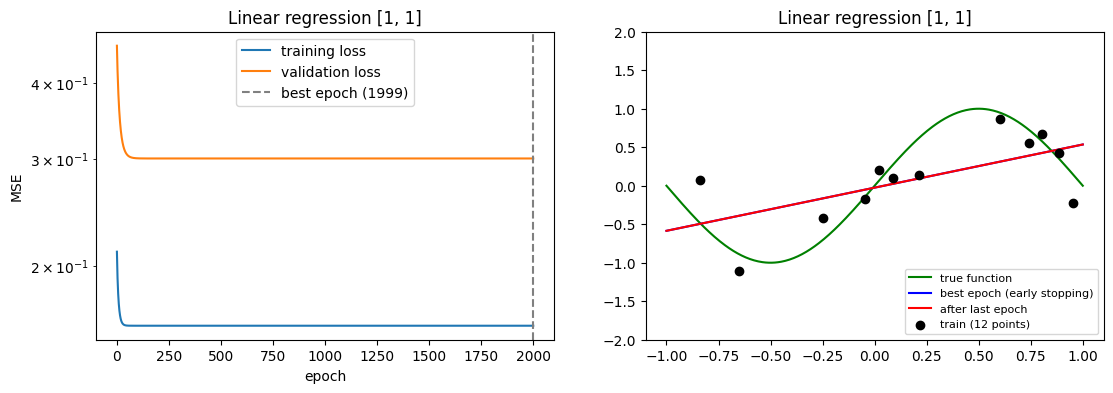

In [16]:
run_linear = train([1, 1], X_train, y_train, X_val, y_val, eta=0.1, epochs=2000)
report(run_linear, "linear")
plot_run(run_linear, "Linear regression [1, 1]")

**Experiment 2 — a deep network on 12 points** (`sizes = [1, 16, 16, 1]`, 321 parameters). This takes a few seconds.

1-16-16-1, 12 points: final train MSE = 0.0022, final val MSE = 0.2936, best val MSE = 0.1356 at epoch 1672


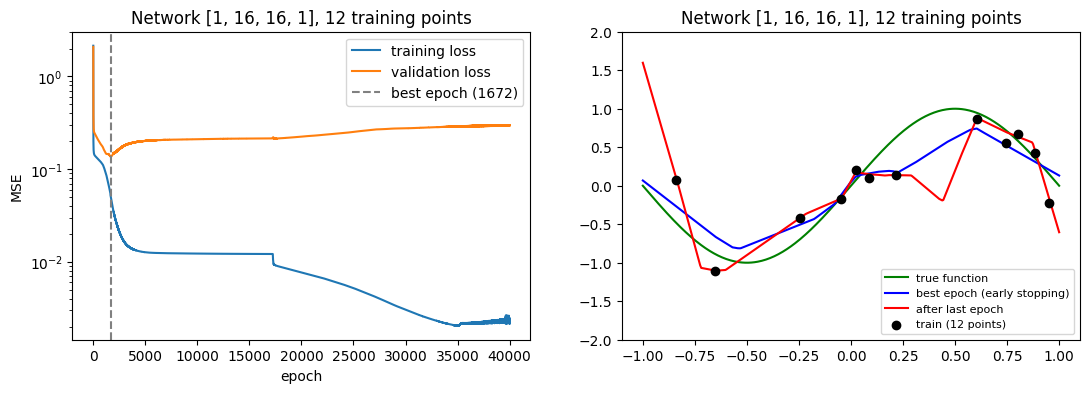

In [18]:
run_deep = train([1, 16, 16, 1], X_train, y_train, X_val, y_val, eta=0.02, epochs=40000)
report(run_deep, "1-16-16-1, 12 points")
plot_run(run_deep, "Network [1, 16, 16, 1], 12 training points")

**Experiment 3 — the same network with 200 training points** (`X_big, y_big`). The function `plot_run` still shows the 12 small-set points; what matters is the loss curve and the red line.

1-16-16-1, 200 points: final train MSE = 0.0719, final val MSE = 0.0701, best val MSE = 0.0670 at epoch 1015


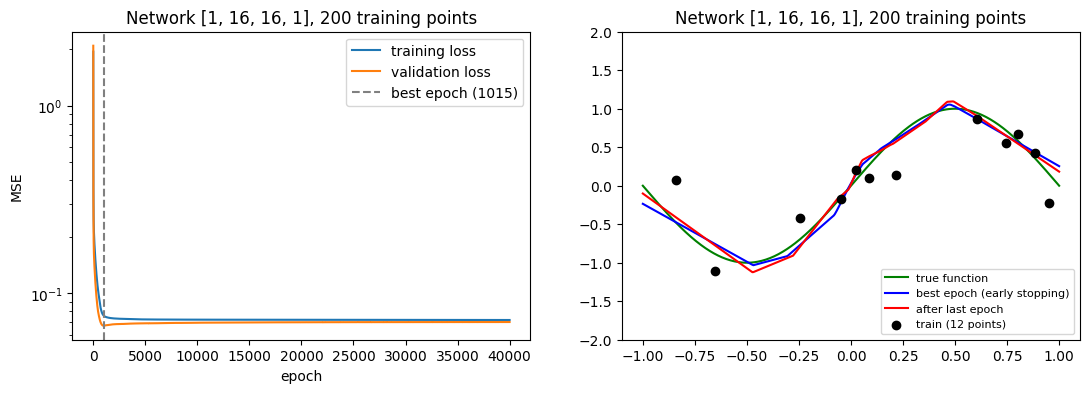

In [19]:
run_big = train([1, 16, 16, 1], X_big, y_big, X_val, y_val, eta=0.02, epochs=40000)
report(run_big, "1-16-16-1, 200 points")
plot_run(run_big, "Network [1, 16, 16, 1], 200 training points")

**Questions (answer in a Markdown cell):**
1. Which experiment shows underfitting, which overfitting? Point to the evidence in the loss curves *and* in the fitted functions. Do the curves look like your drawings in Task 2(a)?
2. In experiment 2 the training loss keeps going down while the validation loss goes up. What is the network doing with the 12 points?
3. Why does the overfitting disappear in experiment 3 although the network is exactly the same? Compare with your sketch in Task 2(b)(iii).
4. The noise in the data has variance $0.25^2 = 0.0625$. Why can no model reach a validation MSE much below this value, and what does it mean if the *training* MSE is far below it?
5. *(Optional)* Try `sizes = [1, 4, 1]` and `[1, 64, 64, 1]` on the 12 points. Are they closer to underfitting or to overfitting?

1-4-1, 12 points: final train MSE = 0.0177, final val MSE = 0.1669, best val MSE = 0.1247 at epoch 7053


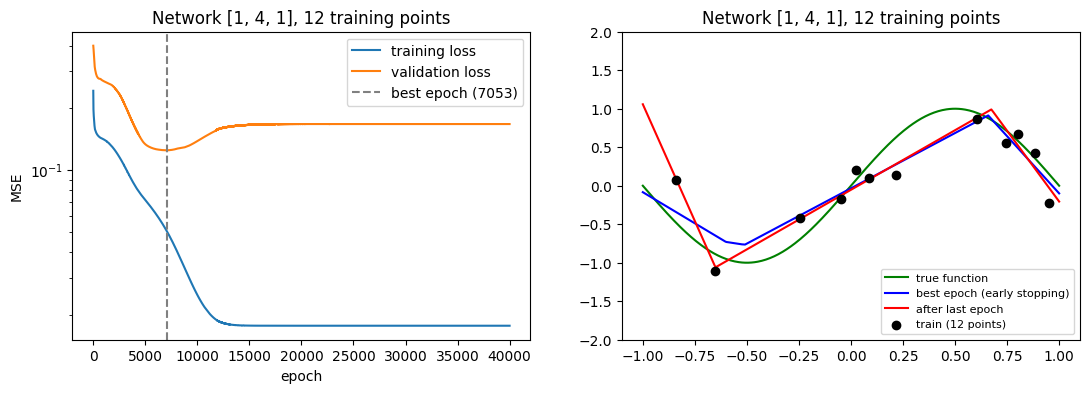

In [21]:
run_1_4_1 = train([1, 4, 1], X_train, y_train, X_val, y_val, eta=0.02, epochs=40000)
report(run_1_4_1, "1-4-1, 12 points")
plot_run(run_1_4_1, "Network [1, 4, 1], 12 training points")

1-64-64-1, 12 points: final train MSE = 0.0015, final val MSE = 0.1884, best val MSE = 0.1255 at epoch 1971


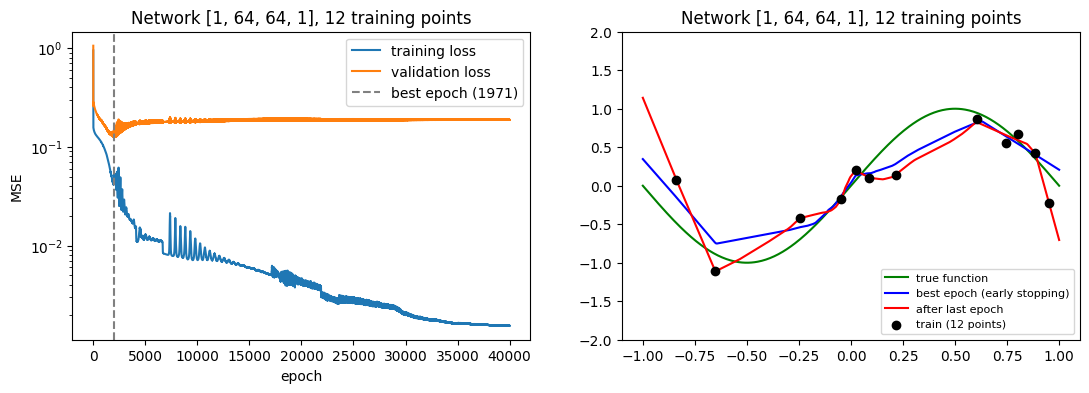

In [22]:
run_deep_64 = train([1, 64, 64, 1], X_train, y_train, X_val, y_val, eta=0.02, epochs=40000)
report(run_deep_64, "1-64-64-1, 12 points")
plot_run(run_deep_64, "Network [1, 64, 64, 1], 12 training points")

*Your answer:*


1.   Experiment 1 underfits because with only one linear function we can't really model a curve and the training and validation loss stays flat after a few epochs. Experiment 2 overfits since its validation loss increases again while the training loss is decreasing. Furthermore, we can see in the plot that the functions follows the points instead of the true function. Experiment 3 looks okay since the training and validation loss gap is small and in the plot we can see that the trained model follows the true function quite good.
2.   The model remembers the positions of the points to minimize the training error intead of trying to learn the underlying pattern between the points.
3. With more training points the model can learn the pattern behind the points instead of memorizing the positions. Also the gap between the training and validation loss decreased with more training but it cant guaranntee that we dont overfit.
4. With the given variance we even would have a loss of the same size if we used a perfect model for the true function. So if a model displays a lower loss it's overfitting.
5. The smaller model is more likely to underfit given that its not so complex and the bigger model is likely to overfit and model the 12 points instead of learning anything.


---
## Task 5(d): Model selection and the test set

We trained on the 12 points and now have three candidate models: the linear model, the deep network after the last epoch, and the deep network at its best epoch (early stopping).
Choose the model with the lowest **validation** MSE, and only then compute its **test** MSE — once.
(Experiment 3 used different training data, so it is not a candidate here.)

In [23]:
candidates = {
    "linear (final)":           run_linear["final_params"],
    "1-16-16-1 (final)":        run_deep["final_params"],
    "1-16-16-1 (early stopped)": run_deep["best_params"],
}

val_errors = {}
for name, p in candidates.items():
    val_errors[name] = loss_fn(p, X_val, y_val)   # TODO: validation MSE of this candidate (hint: loss_fn)
    print(f"{name:28s} validation MSE = {val_errors[name]}")

best_name = min(val_errors, key=val_errors.get)   # the name with the smallest validation MSE
test_error = loss_fn(candidates[best_name], X_test, y_test)   # TODO: test MSE of the chosen model only

print(f"chosen: {best_name}, test MSE = {test_error:.4f}")

linear (final)               validation MSE = 0.30014228453425795
1-16-16-1 (final)            validation MSE = 0.29355591699888306
1-16-16-1 (early stopped)    validation MSE = 0.13563996232005704
chosen: 1-16-16-1 (early stopped), test MSE = 0.1319


**Question (answer in a Markdown cell):** The validation MSE of the chosen model is slightly different from its test MSE. Which of the two numbers would you report as the expected error on new data, and why?

*Your answer:* The test MSE should be reported since its the final estimate on unseen data and the validation MSE could have been used to find good hyperparamters and thus includes a bias.

---
**Done!** Restart the kernel and run all cells before the presentation.